In [1]:
import numpy as np
import pandas as pd

Loading Data to preprocess.

In [2]:
df = pd.read_csv("../data/reddit.csv")
df.head()

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [3]:
df.shape

(37249, 2)

In [4]:
df.sample()["clean_comment"].values

<StringArray>
['this post anti national and anti hindu ']
Length: 1, dtype: str

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 37249 entries, 0 to 37248
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   clean_comment  37149 non-null  str  
 1   category       37249 non-null  int64
dtypes: int64(1), str(1)
memory usage: 582.1 KB


In [6]:
df.isnull().sum()

clean_comment    100
category           0
dtype: int64

In [7]:
df[df['clean_comment'].isna()]

,clean_comment,category
413,NaN,0
605,NaN,0
2422,NaN,0
2877,NaN,0
3307,NaN,0
...,...,...
35975,NaN,0
36036,NaN,0
37043,NaN,0
37111,NaN,0


In [8]:
df[df["clean_comment"].isna()]["category"].value_counts()

category
0    100
Name: count, dtype: int64

In [9]:
# Dropping all missing values for the clean_comments
df.dropna(inplace=True)
df.isnull().sum()

clean_comment    0
category         0
dtype: int64

In [10]:
# checking for duplicate comments and category
df.duplicated().sum()

np.int64(350)

In [11]:
df[df.duplicated()]

,clean_comment,category
375,,0
392,,0
617,aurum mom,0
651,,0
1222,,0
...,...,...
36915,who won,0
37044,,0
37125,hari,0
37158,top kek,1


In [12]:
# Dropping all the duplicates 
df.drop_duplicates(inplace=True)

In [14]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.head()

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [18]:
# Checking for having a new line.
df[(df['clean_comment'].str.strip() == "")]

,clean_comment,category
181,,0
4432,\n,0
10592,,0
16173,,0
32149,\n,0
34959,,0


In [19]:
# Removing the new line from the data
df = df[~(df["clean_comment"].str.strip() == '')]

In [20]:
df[(df['clean_comment'].str.strip() == "")]

,clean_comment,category


In [21]:
# Converting the "clean_comment" column to lowercase
df['clean_comment'] = df['clean_comment'].str.lower()

# Verify the transformation by displaying first 5 rows
df.head()

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1


In [22]:
# Checking for empty spaces at the beginning of the comments or at the end of the comment.
df[df['clean_comment'].apply(lambda x: x.startswith(" ") or x.endswith(" "))]

,clean_comment,category
0,family mormon have never tried explain them t...,1
1,buddhism has very much lot compatible with chr...,1
2,seriously don say thing first all they won get...,-1
3,what you have learned yours and only yours wha...,0
4,for your own benefit you may want read living ...,1
...,...,...
37241,let the janta decide not ulema clerics,0
37242,hona hai same with vaccination education insu...,0
37246,downvote karna tha par upvote hogaya,0
37247,haha nice,1


In [23]:
# Remove trailing and leading white spaces from the "clean_comment" column
df["clean_comment"] = df["clean_comment"].str.strip()

# Verify the transformation by checking the data again
df['clean_comment'].apply(lambda x: x.startswith(" ") or x.endswith(" ")).sum()

np.int64(0)

In [25]:
# Checking comments containing URLs
url_pattern = r'^https?:\/\/(www\.)?[-a-zA-Z0-9@:%._\+~#=]{1,256}\.[a-zA-Z0-9()]{1,63}\b(?:[-a-zA-Z0-9()@:%_\+.~#?&\/=]*)$'
comments_with_urls = df[df['clean_comment'].str.contains(url_pattern, regex=True)]

comments_with_urls.head()

/tmp/ipykernel_35713/182289334.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  comments_with_urls = df[df['clean_comment'].str.contains(url_pattern, regex=True)]


,clean_comment,category


In [26]:
# Checking for comments with new line characters that is `\n`
comments_with_newline = df[df['clean_comment'].str.contains('\n')]

In [27]:
comments_with_newline

,clean_comment,category
448,what missing jpg\nand why this brilliant edit ...,1
781,india has been ruined congress and populist sc...,-1
847,like aap for its stand corruption and making p...,-1
871,reduced trade\ndeficit stronger rupee aren the...,0
1354,amsa press conference australian maritime safe...,1
...,...,...
35128,火箭o辛基 2016 sughosh bansal mission “make india”...,-1
35230,yikes the title should blind bhakts modi hater...,1
36187,hahahahahhahahah \niska klpd hogya,0
36517,्ा् ी ाी े ो ेी ाी े।\nे ी,0


In [28]:
# Remove new line characters from the "clean_comment" column by replacing the \n with space " "
df["clean_comment"] = df["clean_comment"].str.replace('\n', ' ', regex=True)

comments_with_newline_remaining = df[df['clean_comment'].str.contains('\n')]
comments_with_newline_remaining
                                                            

,clean_comment,category


### Exploratory Data Analysis (EDA)
- Definition: data analysis where we explore, summarize, and visualize data to understand its structure, detect patterns, identify anomalies, test assumptions, and check relationships between variables before applying any machine learning or statistical models.

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

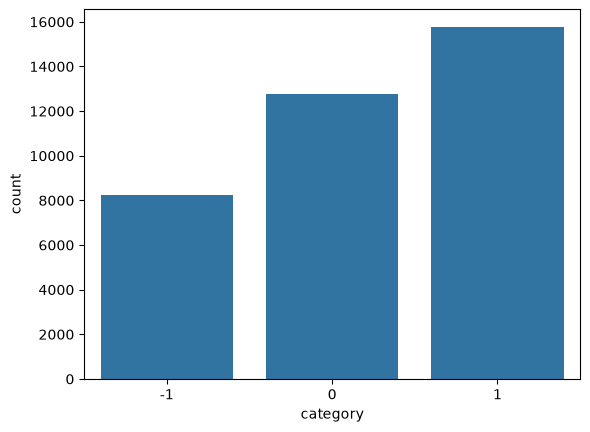

In [33]:
# Distribution of Classes for the categories
# +1 is for positive comments
# -1 is for negative comments
# 0 is for neutral comments

sns.countplot(data = df, x = 'category');

In [34]:
# Frequency distribution of sentiments (percentage distribution)

df['category'].value_counts(normalize=True).mul(100).round(2)

category
 1    42.86
 0    34.71
-1    22.42
Name: proportion, dtype: float64

In [35]:
# Creating a new column to count the words
df['word_count'] = df['clean_comment'].apply(lambda x: len(x.split()))

In [36]:
df.head()

,clean_comment,category,word_count
0,family mormon have never tried explain them th...,1,39
1,buddhism has very much lot compatible with chr...,1,196
2,seriously don say thing first all they won get...,-1,86
3,what you have learned yours and only yours wha...,0,29
4,for your own benefit you may want read living ...,1,112


In [37]:
df.sample(5)

,clean_comment,category,word_count
930,absolutely agree with you subsidies the worst ...,-1,39
16786,you might want add summary what this somewhere...,0,25
8275,sub tale academicbiblical che tratta della rel...,0,20
9719,consensual tagging should allowed and tagging ...,0,12
12263,what are some major differences between public...,1,11


In [38]:
df['word_count'].describe()

count    36793.000000
mean        29.667464
std         56.790738
min          1.000000
25%          6.000000
50%         13.000000
75%         30.000000
max       1307.000000
Name: word_count, dtype: float64

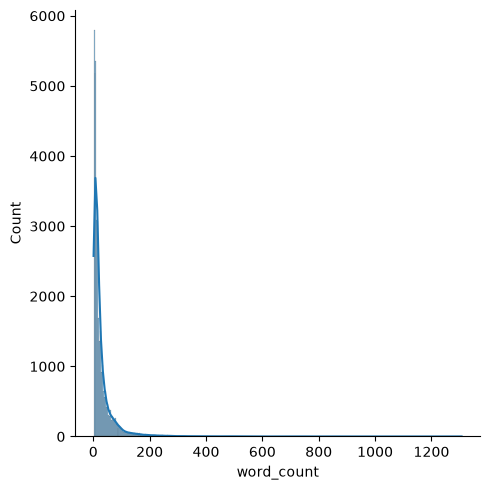

In [39]:
# Distribution plot for the `word_count`
# kde parameter stands for Kernel Density Estimation, which overlays a smooth, continuous curve representing the estimated probability density function of the data. 
sns.displot(df['word_count'], kde=True);

#### Word count Distribution by Category
* Create Figure and axes
* Plot KDE for category 1 (positive comments)
* Plot KDE for category 0 (neutral comments)
* Plot KDE for category -1 (negative comments)
* Add title and labels
- Title = "Word Count Distribution by Category"
- xlabel = "Word Count"
- ylabel = "Density"
* Add a legend
* Show the plot

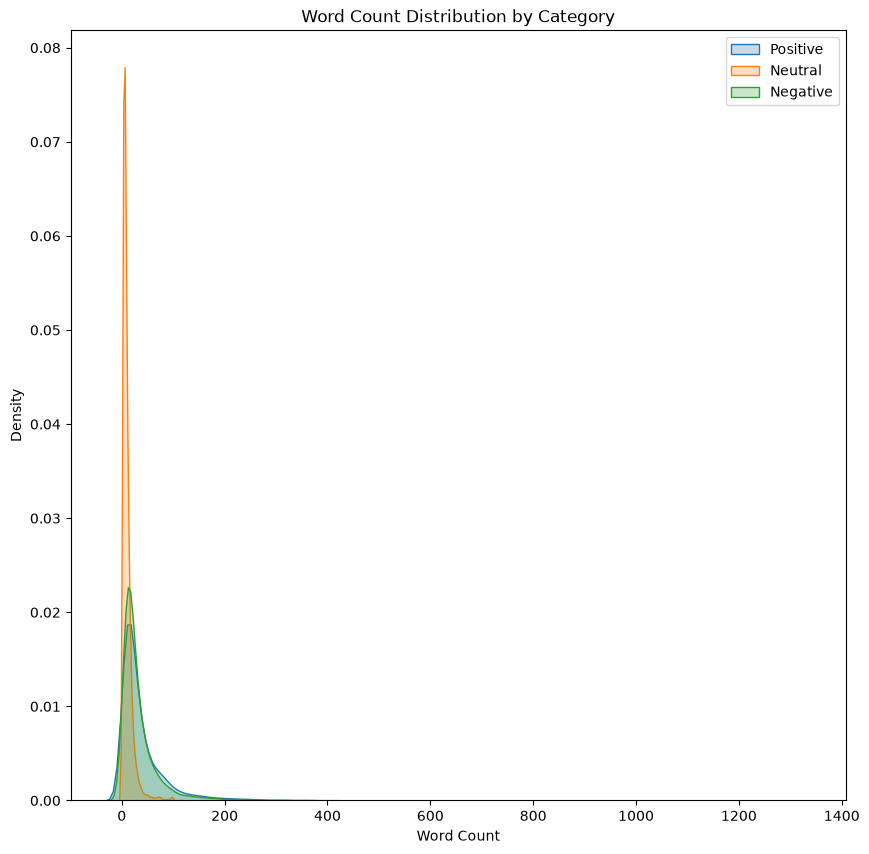

In [40]:
# Create Figure and Axes
plt.figure(figsize=(10, 10))

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == 1]["word_count"], label="Positive", fill=True)

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == 0]["word_count"], label="Neutral", fill=True)

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == -1]["word_count"], label="Negative", fill=True)

# Add Title and Labels
plt.title('Word Count Distribution by Category')
plt.xlabel('Word Count')
plt.ylabel('Density')

# Add a legend
plt.legend()

# Show the plot
plt.show()


### Discussions
**Positive comments (Category 1):** They are having the wider spread in word count, indicating that longer comments are more common in the positive sentiments.

**Neutral comments (Category 0):** The distribution shows a relatively lower frequency and is more concentrated around shorter comments compared to positiver and negative ones.

**Negative comments (Category -1):** These comments have a distribution somewhat similar to positive comments but with a smaller proportion of longer comments.

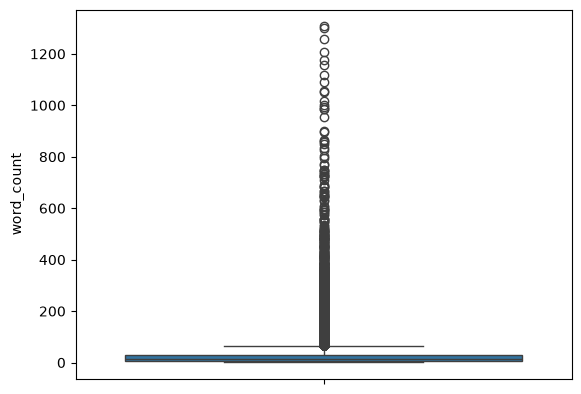

In [42]:
# Plotting Box graph on word count
sns.boxplot(df['word_count']);

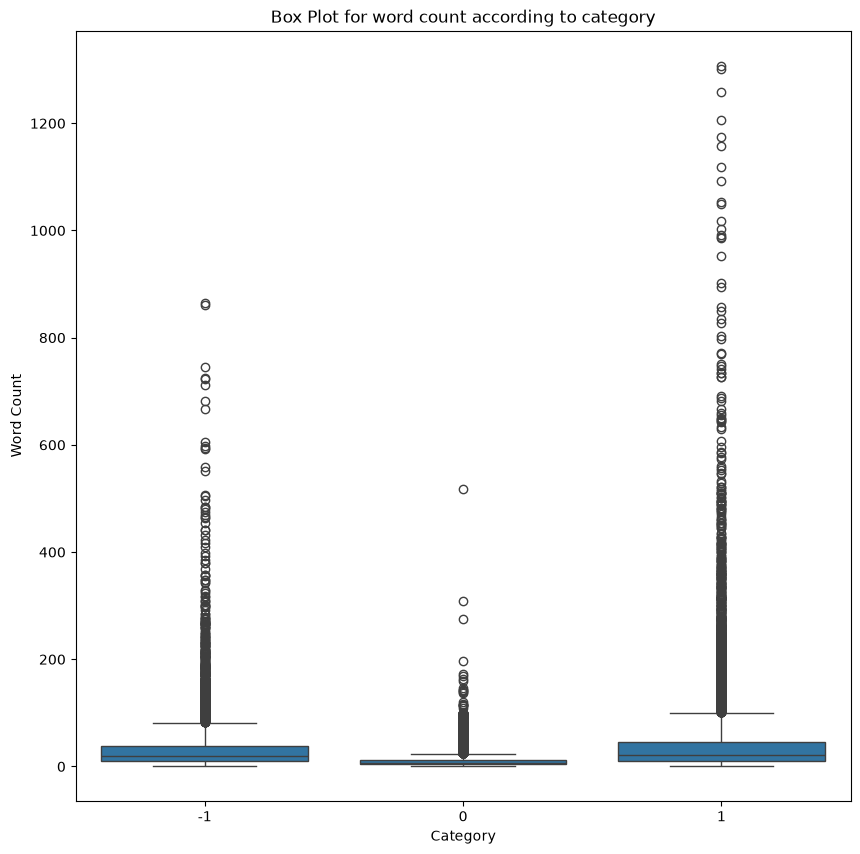

In [43]:
# Plotting a boxplot for the 'word count' column categorized by 'category'
# Defining the figure size
plt.figure(figsize=(10, 10))

# Plotting the boxplot using seaborn
sns.boxplot(data=df, x = "category", y = "word_count")

# Adding titles and labels
plt.title("Box Plot for word count according to category")
plt.xlabel("Category")
plt.ylabel("Word Count")

# Displaying the graph
plt.show()

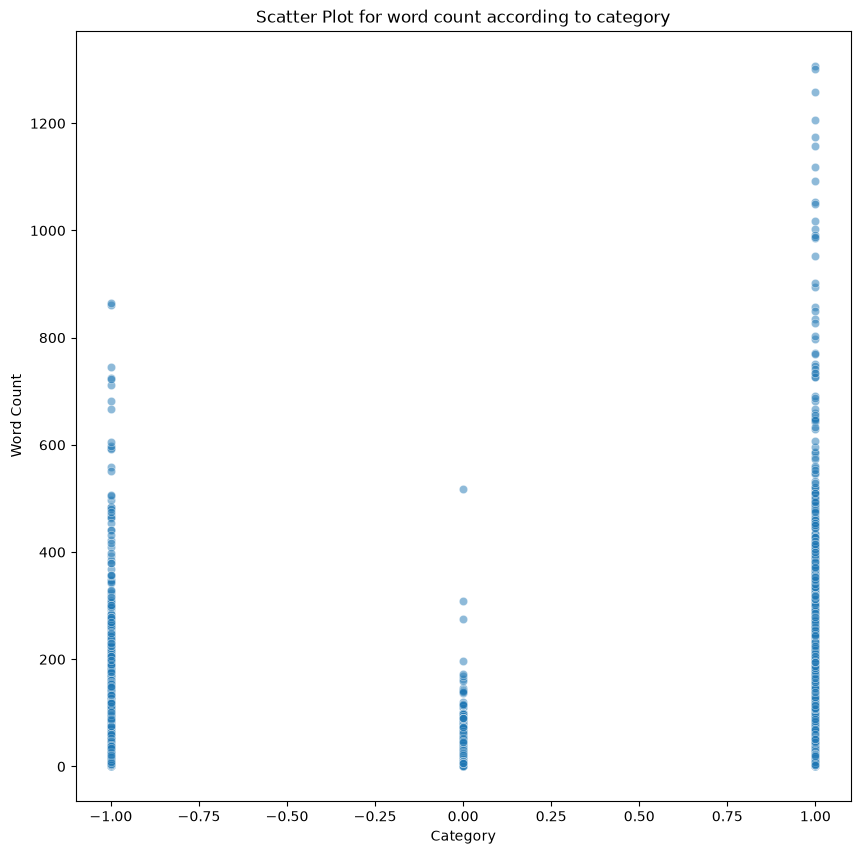

In [44]:
# Plotting a scatter plot for the 'word count' column categorized by 'category'
# Defining the figure size
plt.figure(figsize=(10, 10))

# Plotting the boxplot using seaborn
sns.scatterplot(data=df, x = "category", y = "word_count", alpha=0.5)

# Adding titles and labels
plt.title("Scatter Plot for word count according to category")
plt.xlabel("Category")
plt.ylabel("Word Count")

# Displaying the graph
plt.show()

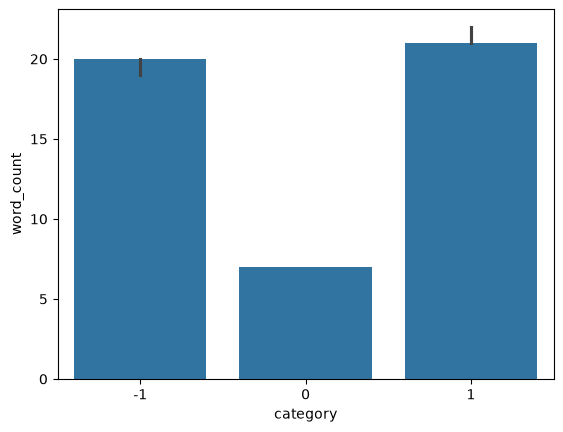

In [45]:
# Plotting a bar plot for median word counts among sentiments
sns.barplot(df, x='category', y='word_count', estimator='median');

## Installed NLTK
NLTK is a leading platform for building Python programs to work with human language data. It provides easy-to-use interfaces to over 50 corpora and lexical resources such as WordNet, along with a suite of text processing libraries for classification, tokenization, stemming, tagging, parsing, and semantic reasoning, wrappers for industrial-strength NLP libraries, and an active discussion forum.

In [48]:
import nltk
from nltk.corpus import stopwords

# If stopwords is not installed in the enviroment, uncomment this
nltk.download("stopwords")

# Define the list of English stopwords
stop_words = set(stopwords.words('english'))

# Create a new column 'num_stop_words' by counting the number of stopwords in each comment
df['num_stop_words'] = df["clean_comment"].apply(lambda x: len([word for word in x.split() if word in stop_words]))

/home/mr-man/Desktop/coding/personal/data-science-lab/env/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/mr-man/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):
[nltk_data] Downloading package stopwords to /home/mr-man/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [49]:
df.sample(5)

,clean_comment,category,word_count,num_stop_words
23000,yes now the perfect time for conspiracy theories,1,8,3
33809,have motherboard with static crackling sound t...,1,26,8
4560,there much grinding poverty india and there bi...,-1,32,10
6159,55934 votes for shivsena,0,4,1
11543,the movie with good point these are not going ...,1,68,35


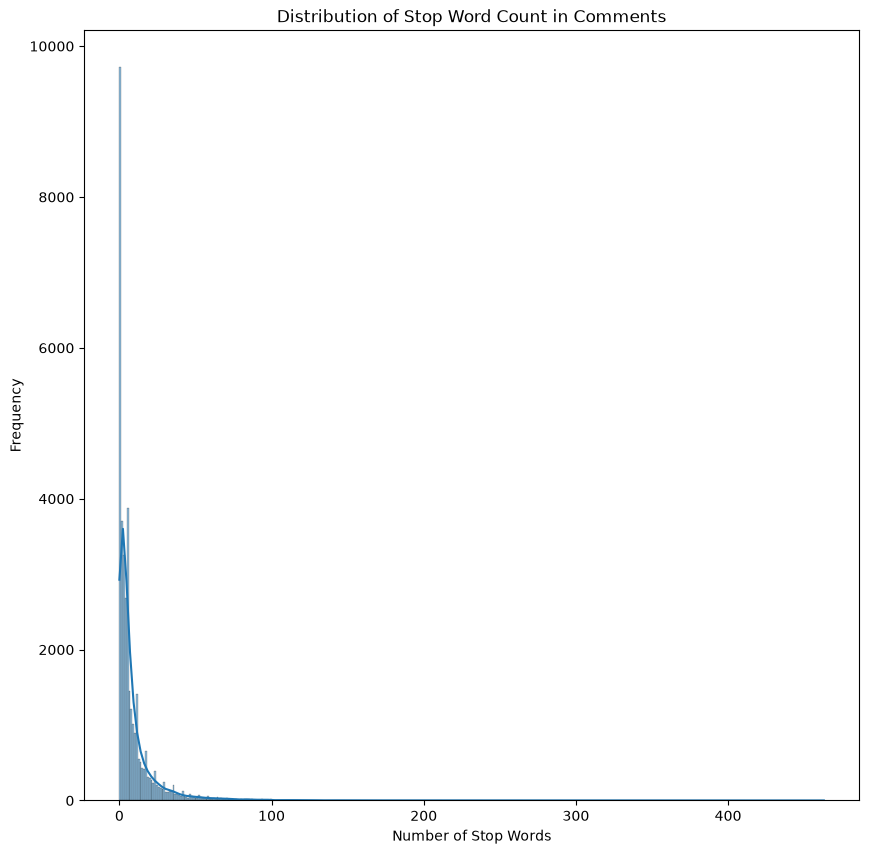

In [50]:
# Plotting a distribution plot for the "num_stop_words" columns
# Define the figure and its size
plt.figure(figsize=(10, 10))

# Plot a histogram graph for the "num_stop_words"
sns.histplot(df["num_stop_words"], kde=True)

# Add title and labels
plt.title("Distribution of Stop Word Count in Comments")
plt.xlabel("Number of Stop Words")
plt.ylabel("Frequency")

# show the graph
plt.show()

#### Stop Words Distribution by Category
* Create Figure and axes
* Plot KDE for category 1 (positive comments)
* Plot KDE for category 0 (neutral comments)
* Plot KDE for category -1 (negative comments)
* Add title and labels
- Title = "Number of Stop Words Distribution by Category"
- xlabel = "Word Count"
- ylabel = "Density"
* Add a legend
* Show the plot

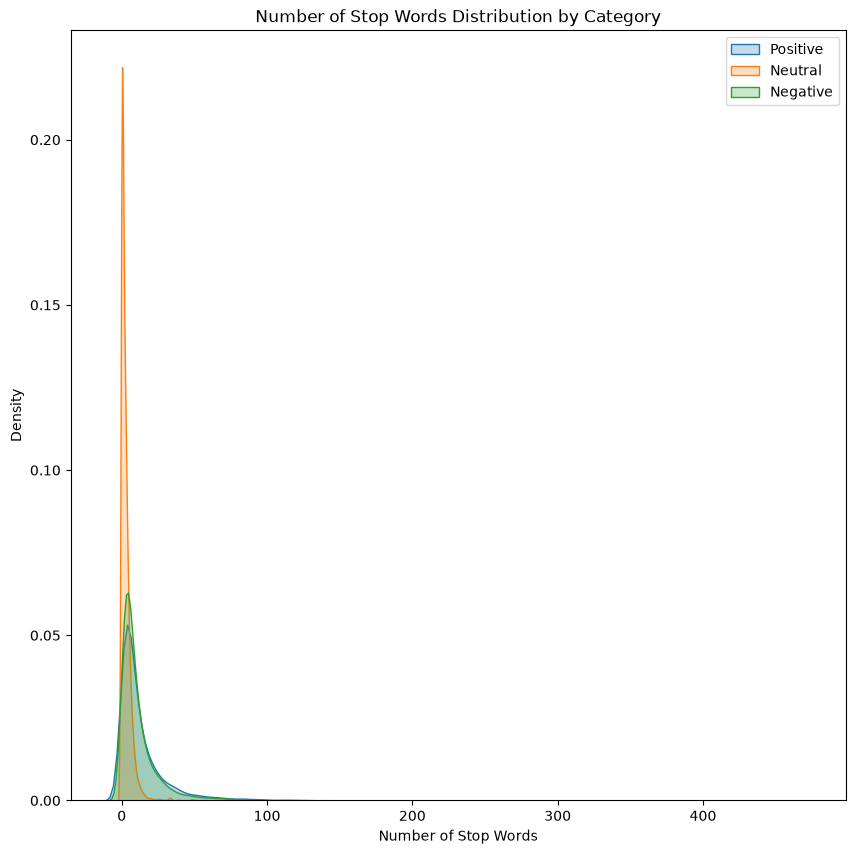

In [52]:
# Create Figure and Axes
plt.figure(figsize=(10, 10))

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == 1]["num_stop_words"], label="Positive", fill=True)

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == 0]["num_stop_words"], label="Neutral", fill=True)

# Plot KDE for category 1 (positive comments)
sns.kdeplot(df[df['category'] == -1]["num_stop_words"], label="Negative", fill=True)

# Add Title and Labels
plt.title('Number of Stop Words Distribution by Category')
plt.xlabel('Number of Stop Words')
plt.ylabel('Density')

# Add a legend
plt.legend()

# Show the plot
plt.show()


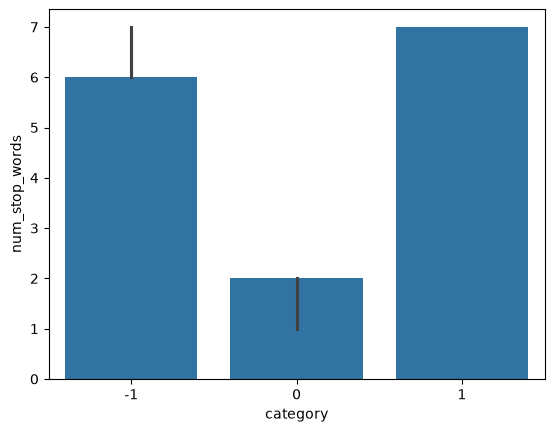

In [53]:
# Plotting a bar plot for median Number of Stop Words among sentiments
sns.barplot(df, x='category', y='num_stop_words', estimator='median');

### Checking the most used stop words from the collection
**Steps:**
1. Create a frequency distribution of stop words in the "clean_comment" column
2. Extract all stop words from teh comments using the defined "num_stop_words"
3. Count the most common stop words
4. Convert the most common stop words to a DataFrame for plotting
5. Create the barplot for the top 30 most common stop words

Checking all the stop words
they
Counting the most common stop words
[('the', 57669), ('and', 28950), ('that', 15372), ('this', 13463), ('for', 12976), ('you', 11723), ('are', 10566), ('not', 8691), ('they', 8654), ('have', 8380), ('with', 7845), ('but', 7264), ('will', 6905), ('was', 6371), ('what', 5270), ('all', 5130), ('has', 5097), ('can', 5037), ('from', 4965), ('about', 4355), ('just', 4261), ('there', 4150), ('who', 4058), ('their', 3938), ('his', 3341), ('how', 3337), ('more', 3280), ('your', 3143), ('now', 3044), ('don', 3021)]
Defining the most 30 common stop words
Plotting barplot for the most 30 common stop words


/tmp/ipykernel_35713/3738027799.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_30_df, x="count", y="stop_word", palette="viridis")


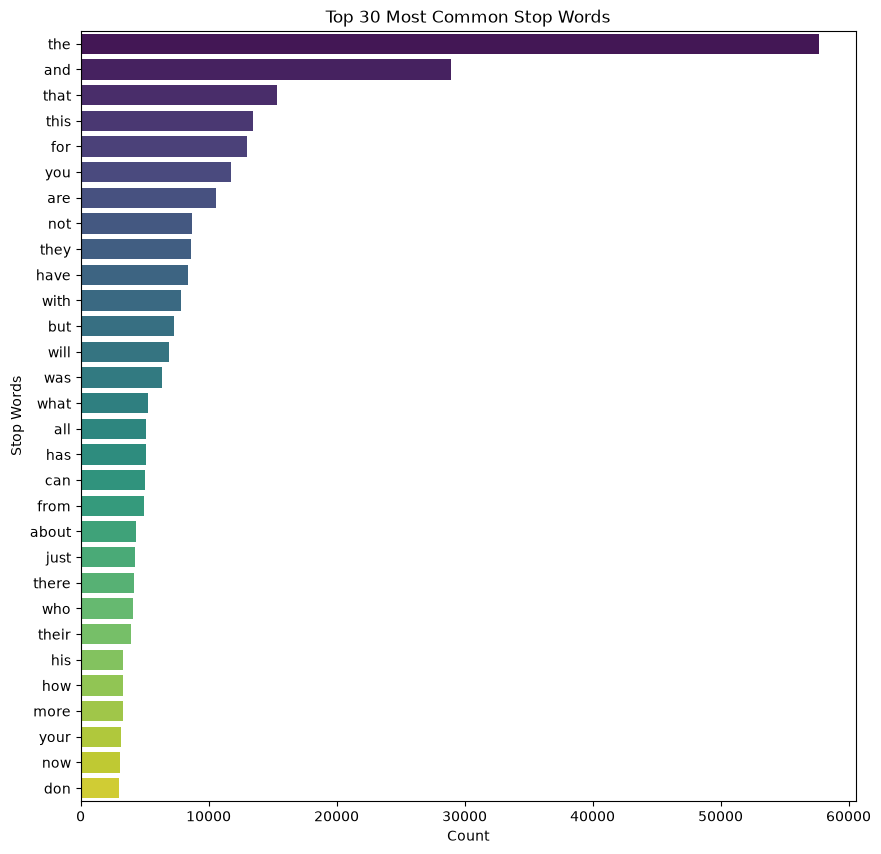

In [56]:
# Create a frequency distribution of stop words in the "clean_comment" column
from collections import Counter

# Extract all stop words from teh comments using the defined "num_stop_words" Here a nested list comprehension was used
# print("Checking all the stop words")
all_stop_words = [word for comment in df["clean_comment"] for word in comment.split() if word in stop_words]
# print(all_stop_words[5])

# Count the most common stop words
# print("Counting the most common stop words")
most_common_stop_words = Counter(all_stop_words).most_common(30)
# print(most_common_stop_words)

# Convert the most common stop words to a DataFrame for plotting
top_30_df = pd.DataFrame(most_common_stop_words, columns=["stop_word", "count"])

# Create the barplot for the top 30 most common stop words
plt.figure(figsize=(10, 10))
sns.barplot(data=top_30_df, x="count", y="stop_word", hue="stop_word", palette="viridis", lege )
plt.title("Top 30 Most Common Stop Words")
plt.xlabel("Count")
plt.ylabel("Stop Words")
plt.show()